# 4 FORECASTING

**Project:** Irish Milk Supply: Growth, Seasonality and Forecasting

**Author:** Temuulen Bulgan

### Purpose of this notebook
Notebook 3 showed a strong seasonal pattern that repeats every year, and a long-term trend that changed after EU milk quotas ended in 2015. This notebook tests how well monthly milk intake can be forecast from past data. It compares simple and more complex models, and checks whether a model that learns the trend still works when the trend changes.

### Input
The `dairy` database in SQL Server, loaded in notebook 2.

### Output
Charts saved in the `figures/` folder and the forecast accuracy (MAPE) of each model.

## Setup

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sqlalchemy import create_engine
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX

#### Connect to the database

In [2]:
# Connection to the dairy database on this computer
engine = create_engine(
    "mssql+pyodbc://@localhost/dairy"
    "?driver=ODBC+Driver+18+for+SQL+Server"
    "&trusted_connection=yes"
    "&TrustServerCertificate=yes",
)

# Test the connection: list the tables in the dairy database
pd.read_sql("SELECT name FROM sys.tables ORDER BY name", engine)

,name
0,dim_date
1,dim_measure
2,fact_monthly


## 1. Load the data

The forecasts use one measure: monthly milk intake by processors (`intake_ml`, million litres). It is read from the database in the same way as in notebook 3, but only for this measure.

In [3]:
# Monthly milk intake, with its date from dim_date
query = """
    SELECT
        f.date_key,
        f.value
    FROM fact_monthly AS f
    JOIN dim_date AS d
        ON f.date_key = d.date_key
    WHERE f.measure_code = 'intake_ml'
    ORDER BY f.date_key;
"""

data = pd.read_sql(query, engine, parse_dates=["date_key"])

print(data.shape)
display(data.head(3))
display(data.tail(3))

(620, 2)


,date_key,value
0,1975-01-01,55.8
1,1975-02-01,84.4
2,1975-03-01,193.3


,date_key,value
617,2026-06-01,1044.1
618,2026-07-01,980.2
619,2026-08-01,865.3


There are 620 monthly values, from January 1975 to August 2026.

### 1.1 Monthly time series

The forecasting models in statsmodels need a series with a date index and a fixed frequency. `asfreq("MS")` sets the frequency to monthly, with dates on the first day of each month. If a month were missing, `asfreq` would add it as an empty value, so the check below also shows whether there are gaps.

In [4]:
# Dates as the index, intake as the values
intake = data.set_index("date_key")["value"]
intake.name = "intake_ml"

# Fixed monthly frequency, first day of each month
intake = intake.asfreq("MS")

print(intake.index.freq)
print(len(intake), "months")
print(intake.isna().sum(), "missing values")

<MonthBegin>
620 months
0 missing values


The series has 620 months with no gaps and no missing values, so the models can use it directly.

## 2. How forecast accuracy is measured

Each model is tested the way it would be used in practice: every December it is trained on all data up to that month, and it forecasts the next 12 months. The forecast is then compared with what really happened.

- **Backtest:** forecasts for each year from 2017 to 2022, a period of steady growth.
- **Hold-out test:** forecasts for 2023, 2024, 2025 and January–August 2026, the period after growth stopped.

Both use the same method and the same 12-month horizon, so their results can be compared.

Accuracy is measured with the **mean absolute percentage error (MAPE)**. For each month, the error is the gap between the forecast and the actual value, as a percentage of the actual value. MAPE is the average of these percentages. Lower is better: a MAPE of 5% means the forecasts were off by 5% on average.

In [5]:
# Mean absolute percentage error: the average size of the error, as a % of the actual value
def mape(actual, forecast):
    errors = (actual - forecast).abs() / actual
    return errors.mean() * 100


# Check with numbers that are easy to work out by hand
check_actual = pd.Series([100, 200])
check_forecast = pd.Series([110, 160])

print(round(mape(check_actual, check_forecast), 2))

15.0


The check gives 15%, the average of a 10% and a 20% error, so the function works as intended.

## 3. Seasonal naive model

The simplest forecast: each month will be the same as the same month last year. It copies the seasonal pattern exactly but assumes no growth. It is the baseline: a more complex model is only worth using if it beats this.

All three models are written as functions that take the training data and the number of months to forecast, and return a forecast with monthly dates. This way the same evaluation code can be used for every model.

In [6]:
# Seasonal naive: each month is the same as the same month last year
def seasonal_naive(train, horizon):
    last_12_months = train.iloc[-12:]

    # Monthly dates for the forecast, starting the month after the training data ends
    forecast_dates = pd.date_range(
        start=train.index[-1] + pd.DateOffset(months=1),
        periods=horizon,
        freq="MS",
    )

    return pd.Series(last_12_months.iloc[:horizon].values, index=forecast_dates)


# Test on one year: train up to December 2024, forecast 2025
train = intake.loc[:"2024-12"]
test = intake.loc["2025"]

forecast = seasonal_naive(train, len(test))

comparison = pd.DataFrame({"actual": test, "forecast": forecast})

# Error for each month as a % of the actual value (positive = forecast too high)
comparison["error_pct"] = ((forecast - test) / test * 100).round(1)

display(comparison)
print("MAPE:", round(mape(test, forecast), 2), "%")

,actual,forecast,error_pct
2025-01-01,162.5,148.47,-8.6
2025-02-01,327.8,351.90,7.4
2025-03-01,821.8,757.20,-7.9
2025-04-01,1074.5,952.00,-11.4
2025-05-01,1183.4,1107.40,-6.4
2025-06-01,1080.5,1031.20,-4.6
2025-07-01,1004.9,972.40,-3.2
2025-08-01,944.8,887.20,-6.1
2025-09-01,773.2,767.70,-0.7
2025-10-01,706.1,673.10,-4.7


MAPE: 5.6 %


The forecast for 2025 is simply the 2024 values. The error is negative in 9 of the 12 months, so the forecast is too low in most months, because 2025 intake was higher than 2024. The largest error is in April (−11.4%). On average the forecast is 5.6% off.

### 3.1 Backtest and hold-out results

The function `evaluate` repeats the test from above for each year: train on all data up to the previous December, forecast the year, and calculate the MAPE. The same function is used for all three models.

In [7]:
# Forecast years for each test
backtest_years = range(2017, 2023)
holdout_years = range(2023, 2027)


# MAPE for each year: train up to the previous December, forecast that year
def evaluate(model, years):
    results = {}

    for year in years:
        train = intake.loc[: f"{year - 1}-12"]
        test = intake.loc[str(year)]

        forecast = model(train, len(test))
        results[year] = mape(test, forecast)

    return pd.Series(results)


naive_backtest = evaluate(seasonal_naive, backtest_years)
naive_holdout = evaluate(seasonal_naive, holdout_years)

print("Backtest MAPE by year (%):")
print(naive_backtest.round(2))
print("Average:", round(naive_backtest.mean(), 2), "%")

print()
print("Hold-out MAPE by year (%):")
print(naive_holdout.round(2))
print("Average:", round(naive_holdout.mean(), 2), "%")

Backtest MAPE by year (%):
2017    8.35
2018    7.85
2019    7.19
2020    4.08
2021    4.77
2022    2.55
dtype: float64
Average: 5.8 %

Hold-out MAPE by year (%):
2023    8.12
2024    9.86
2025    5.60
2026    3.85
dtype: float64
Average: 6.86 %


In the backtest, the seasonal naive forecast is off by 5.8% on average. The error is largest in 2017–2019, when intake grew fastest, because the model assumes no growth. In the hold-out test, the average error is 6.86%. 2023 and 2024 have the largest errors, even though yearly intake hardly changed in those years.

## 4. Holt-Winters model

Holt-Winters (exponential smoothing) follows three things over time: the level of intake, the trend (growth per month) and the seasonal pattern. Recent months count more than older ones, so the model adapts when things change.

Settings:
- **Seasonal pattern as percentages** (`seasonal="mul"`): each month is a percentage above or below the level. The size of the seasonal swing has almost doubled since the 1970s, so a fixed amount per month would not fit.
- **Damped trend** (`damped_trend=True`): the forecast growth slowly flattens out instead of continuing at the same rate forever.

In [8]:
# Holt-Winters: level, damped trend and a seasonal pattern in percentages
def holt_winters(train, horizon):
    model = ExponentialSmoothing(
        train,
        trend="add",
        damped_trend=True,
        seasonal="mul",
        seasonal_periods=12,
        initialization_method="heuristic",
    )
    fitted = model.fit()

    return fitted.forecast(horizon)


# Test on one year: train up to December 2024, forecast 2025
train = intake.loc[:"2024-12"]
test = intake.loc["2025"]

forecast = holt_winters(train, len(test))

comparison = pd.DataFrame({"actual": test, "forecast": forecast.round(1)})

# Error for each month as a % of the actual value (positive = forecast too high)
comparison["error_pct"] = ((forecast - test) / test * 100).round(1)

display(comparison)
print("MAPE:", round(mape(test, forecast), 2), "%")

,actual,forecast,error_pct
2025-01-01,162.5,171.5,5.5
2025-02-01,327.8,370.0,12.9
2025-03-01,821.8,799.2,-2.8
2025-04-01,1074.5,1022.6,-4.8
2025-05-01,1183.4,1166.5,-1.4
2025-06-01,1080.5,1070.3,-0.9
2025-07-01,1004.9,1019.8,1.5
2025-08-01,944.8,921.2,-2.5
2025-09-01,773.2,785.9,1.6
2025-10-01,706.1,665.1,-5.8


MAPE: 4.16 %


For 2025, Holt-Winters is off by 4.16% on average, compared with 5.6% for the seasonal naive forecast. The largest error is in February (+12.9%), where the forecast is too high.

### 4.1 Backtest and hold-out results

The same `evaluate` function from Section 3.1 is used, now with `holt_winters`. The model is refitted every year on all data up to the previous December.

In [9]:
hw_backtest = evaluate(holt_winters, backtest_years)
hw_holdout = evaluate(holt_winters, holdout_years)

print("Backtest MAPE by year (%):")
print(hw_backtest.round(2))
print("Average:", round(hw_backtest.mean(), 2), "%")

print()
print("Hold-out MAPE by year (%):")
print(hw_holdout.round(2))
print("Average:", round(hw_holdout.mean(), 2), "%")

Backtest MAPE by year (%):
2017    8.27
2018    7.78
2019    3.46
2020    4.55
2021    4.87
2022    2.37
dtype: float64
Average: 5.22 %

Hold-out MAPE by year (%):
2023    8.93
2024    5.98
2025    4.16
2026    3.17
dtype: float64
Average: 5.56 %


Holt-Winters has an average error of 5.22% in the backtest and 5.56% in the hold-out test. Both are lower than the seasonal naive forecast (5.8% and 6.86%, Section 3.1). Its largest error is in 2023 (8.93%), the first year after growth stopped.

## 5. SARIMA model

SARIMA works with changes instead of levels. The model (0,1,1)(0,1,1)12 looks at two differences: the change from last month and the change from the same month last year. It then forecasts these changes from its recent errors. This is a standard model for monthly data with a seasonal pattern.

The model is fitted on the log of intake. On a log scale, a percentage change becomes a fixed amount, so the seasonal pattern in percentages fits the model. The forecast is changed back to million litres with the exponential function (`np.exp`), the reverse of the log.

In [10]:
# SARIMA (0,1,1)(0,1,1)12 on log intake, forecast changed back to million litres
def sarima(train, horizon):
    model = SARIMAX(
        np.log(train),
        order=(0, 1, 1),
        seasonal_order=(0, 1, 1, 12),
    )
    fitted = model.fit(disp=False)
    log_forecast = fitted.forecast(horizon)

    return np.exp(log_forecast)


# Test on one year: train up to December 2024, forecast 2025
train = intake.loc[:"2024-12"]
test = intake.loc["2025"]

forecast = sarima(train, len(test))

comparison = pd.DataFrame({"actual": test, "forecast": forecast.round(1)})

# Error for each month as a % of the actual value (positive = forecast too high)
comparison["error_pct"] = ((forecast - test) / test * 100).round(1)

display(comparison)
print("MAPE:", round(mape(test, forecast), 2), "%")

,actual,forecast,error_pct
2025-01-01,162.5,187.7,15.5
2025-02-01,327.8,408.6,24.6
2025-03-01,821.8,884.3,7.6
2025-04-01,1074.5,1130.6,5.2
2025-05-01,1183.4,1290.8,9.1
2025-06-01,1080.5,1185.6,9.7
2025-07-01,1004.9,1130.8,12.5
2025-08-01,944.8,1022.8,8.3
2025-09-01,773.2,874.3,13.1
2025-10-01,706.1,739.9,4.8


MAPE: 10.59 %


For 2025, SARIMA is off by 10.59% on average, compared with 4.16% for Holt-Winters and 5.6% for the seasonal naive forecast. The error is positive in all 12 months, so the forecast is too high in every month.

### 5.1 Backtest and hold-out results

The same `evaluate` function is used, now with `sarima`.

In [11]:
sarima_backtest = evaluate(sarima, backtest_years)
sarima_holdout = evaluate(sarima, holdout_years)

print("Backtest MAPE by year (%):")
print(sarima_backtest.round(2))
print("Average:", round(sarima_backtest.mean(), 2), "%")

print()
print("Hold-out MAPE by year (%):")
print(sarima_holdout.round(2))
print("Average:", round(sarima_holdout.mean(), 2), "%")

Backtest MAPE by year (%):
2017     5.02
2018     9.30
2019    23.91
2020     1.76
2021     3.80
2022     2.21
dtype: float64
Average: 7.67 %

Hold-out MAPE by year (%):
2023    16.79
2024    21.63
2025    10.59
2026     4.05
dtype: float64
Average: 13.27 %


SARIMA has an average error of 7.67% in the backtest and 13.27% in the hold-out test, the highest of the three models in both. In some years it is the most accurate model (2020: 1.76%, 2022: 2.21%), but in others its error is very large (2019: 23.91%, 2024: 21.63%).

## 6. Comparison of the three models

The MAPE of each model for every forecast year, and the average for the backtest (2017–2022) and the hold-out test (2023–2026).

In [12]:
# MAPE by year: backtest and hold-out years together, one column per model
by_year = pd.DataFrame({
    "Seasonal naive": pd.concat([naive_backtest, naive_holdout]),
    "Holt-Winters": pd.concat([hw_backtest, hw_holdout]),
    "SARIMA": pd.concat([sarima_backtest, sarima_holdout]),
})
by_year.index.name = "year"

display(by_year.round(2))

# Average MAPE for each model and each test
averages = pd.DataFrame(
    {
        "Backtest 2017–2022": [
            naive_backtest.mean(),
            hw_backtest.mean(),
            sarima_backtest.mean(),
        ],
        "Hold-out 2023–2026": [
            naive_holdout.mean(),
            hw_holdout.mean(),
            sarima_holdout.mean(),
        ],
    },
    index=["Seasonal naive", "Holt-Winters", "SARIMA"],
)

display(averages.round(2))

,Seasonal naive,Holt-Winters,SARIMA
year,,,
2017,8.35,8.27,5.02
2018,7.85,7.78,9.30
2019,7.19,3.46,23.91
2020,4.08,4.55,1.76
2021,4.77,4.87,3.80
2022,2.55,2.37,2.21
2023,8.12,8.93,16.79
2024,9.86,5.98,21.63
2025,5.60,4.16,10.59


,Backtest 2017–2022,Hold-out 2023–2026
Seasonal naive,5.80,6.86
Holt-Winters,5.22,5.56
SARIMA,7.67,13.27


Holt-Winters has the lowest average error in both tests (5.22% and 5.56%). The seasonal naive forecast is second in both.

SARIMA has the highest average error, but it is the most accurate model in 4 of the 6 backtest years (2017, 2020, 2021, 2022). Its average is high because of a few very large errors, mainly 2019 (23.91%) in the backtest and 2023–2024 (16.79% and 21.63%) in the hold-out.

All three models are less accurate in the hold-out test than in the backtest. The increase is small for Holt-Winters (5.22% to 5.56%) and large for SARIMA (7.67% to 13.27%).

### 6.1 Forecast error by year

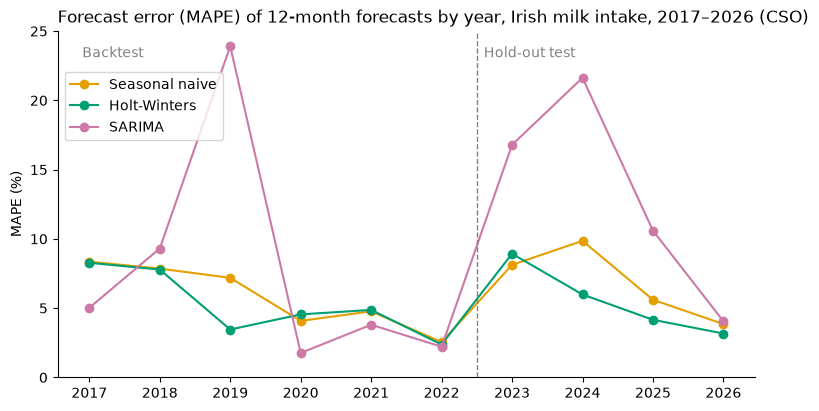

In [13]:
# Colours by role: seasonal naive as the grey baseline, the two models in blue
line_colours = {
    "Seasonal naive": "#E69F00",
    "Holt-Winters": "#009E73",
    "SARIMA": "#CC79A7",
}

# One line per model
fig, ax = plt.subplots(figsize=(9, 4.5))
for model_name in by_year.columns:
    ax.plot(
        by_year.index,
        by_year[model_name],
        marker="o",
        color=line_colours[model_name],
        label=model_name,
    )

# Line between the backtest and the hold-out test, with a label on each side
top = by_year.max().max()
ax.axvline(2022.5, color="grey", linestyle="--", linewidth=1)
ax.text(2016.9, top, "Backtest", va="top", color="grey")
ax.text(2022.6, top, "Hold-out test", va="top", color="grey")

# Detailed title and labels
ax.set_title(
    "Forecast error (MAPE) of 12-month forecasts by year, Irish milk intake, 2017–2026 (CSO)",
    loc="left",
)
ax.set_ylabel("MAPE (%)")
ax.set_xticks(by_year.index)
ax.set_ylim(bottom=0)
ax.legend(loc="upper left", bbox_to_anchor=(0, 0.9))

# Remove the top and right frame lines
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Save the chart and show it
fig.savefig("../figures/04_mape_by_year.png", dpi=150, bbox_inches="tight")
plt.show()

### 6.2 Why SARIMA has large errors

SARIMA forecasts changes, not levels. If the last months of the training data were much higher or lower than a year earlier, SARIMA may carry that change into the whole next year.

To test this, two numbers are calculated for each forecast year:
- **Late-year change:** intake in October–December of the previous year, compared with October–December one year before that (%).
- **SARIMA bias:** the average error with its sign kept (%). Positive means the forecast was too high on average, negative means too low.

If the explanation is right, the two numbers should move together.

In [14]:
# Late-year change in the training data and SARIMA's average signed error, for each forecast year
rows = []

for year in list(backtest_years) + list(holdout_years):
    train = intake.loc[: f"{year - 1}-12"]
    test = intake.loc[str(year)]
    forecast = sarima(train, len(test))

    # October–December of the last training year, and the same months one year earlier
    last_three_months = train.iloc[-3:].sum()
    same_months_year_before = train.iloc[-15:-12].sum()
    late_year_change = (last_three_months / same_months_year_before - 1) * 100

    # Average error with its sign kept
    bias = ((forecast - test) / test * 100).mean()

    rows.append({
        "year": year,
        "late_year_change_pct": late_year_change,
        "sarima_bias_pct": bias,
    })

sarima_check = pd.DataFrame(rows).set_index("year")
display(sarima_check.round(1))

print(
    "Correlation:",
    round(sarima_check["late_year_change_pct"].corr(sarima_check["sarima_bias_pct"]), 2),
)

,late_year_change_pct,sarima_bias_pct
year,,
2017,-4.7,-5.0
2018,10.3,4.7
2019,21.5,23.9
2020,-7.2,0.3
2021,7.2,2.3
2022,1.4,-0.4
2023,6.2,16.8
2024,-19.5,-21.6
2025,23.6,10.6


Correlation: 0.86


The late-year change and SARIMA's bias move together (correlation 0.86). Intake at the end of 2018 was 21.5% higher than a year earlier, and SARIMA's 2019 forecast was 23.9% too high. At the end of 2023 intake was 19.5% lower, and the 2024 forecast was 21.6% too low.

So SARIMA's large errors come from carrying a short-term change at the end of the year into the whole next year. 2023 does not fit this pattern well: the late-2022 change was only 6.2%, but the 2023 forecast was 16.8% too high. With only 10 years, the correlation is a rough guide, not a precise measure.

## 7. Summary of findings

1. **Holt-Winters is the most reliable model.** It has the lowest average error in both the backtest (5.22%) and the hold-out test (5.56%), and its error stays below 10% in every year. Its accuracy changed little when growth stopped after 2022.
2. **The seasonal naive forecast is a strong baseline.** Copying last year's months gives an average error of 5.8% in the backtest and 6.86% in the hold-out test, second in both. A more complex model has to beat this to be worth using.
3. **SARIMA is often the most accurate, but sometimes very wrong.** It is the best model in 4 of the 6 backtest years, but has errors above 15% in 2019, 2023 and 2024. Its average error is the highest in both tests (7.67% and 13.27%).
4. **SARIMA's large errors come from short-term changes at the end of the year.** When intake in October–December was much higher or lower than a year earlier, SARIMA carried that change into the whole next year (correlation 0.86 between the late-year change and SARIMA's bias). 2023 is an exception.
5. **The seasonal pattern can be forecast; the trend is harder.** All three models were less accurate after growth stopped in 2023. For planning, a model like Holt-Winters gives a stable monthly profile, but the level of next year's intake is better treated as a range of scenarios (for example, no growth or moderate growth) than as one number.

**Limitations**
- Only past intake is used. Weather, milk prices and herd numbers are not in the models, so years like 2023–2024 cannot be explained.
- Results come from 10 forecast years, so the averages and the correlation are rough guides.
- MAPE gives more weight to winter months, when intake is low, so a small error in January counts more than a large one in May.
- Each model was run with one set of settings chosen in advance and was not tuned. Other settings could give different results.
- 2026 includes only January to August.